# What to leave out, and the appendix: where does the rest go?

**Week 4, Tuesday, concept notebook 2 of 5, beside chapter 2 of the deck.** Ramesh's kirana
shop returns from notebook 01 with the same invented numbers; only the question changes.
Notebook 01 found that his decision is priced per hour: Rs 1,190 an hour in September and
Rs 1,050 in October.

**Who needs the answer.** Ramesh (invented), who reads the slide in five minutes, and two
readers who each look for their own question behind it: his son and the shop's accountant.
A slide that keeps everything buries the claim, and a slide that drops the caveat is called
dishonest by the first reader who finds it missing.

**The questions on the way.** How many of the draft's eight elements stay? Where does each
of the rest go? Can the caveat leave when the slide is crowded? Does a chart obey the same
rule?

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

# Ramesh's first draft: eight elements, what each shows, and who would ask about it; all invented
elements = pd.read_csv("../data/C2_W04_D02_kirana_slide_elements_STUDENT.csv").fillna("")
check("eight elements on the first draft", len(elements) == 8)
check("exactly one element is the caveat", (elements.is_caveat == "yes").sum() == 1)
print(elements.to_string(index=False))

PASS eight elements on the first draft
PASS exactly one element is the caveat
                       element                                        what_it_shows supports_claim whose_question is_caveat
 Chart: sales per hour, by day   Rs 1,190 an hour in September, Rs 1,050 in October            yes                       no
       Total sales, four weeks   Rs 3.33 lakh in September, Rs 3.53 lakh in October             no the accountant        no
               Customers a day                     119 in September, 126 in October             no        the son        no
                     Rain days                         5 in September, 2 in October             no                       no
The son's hours at the counter                   4 a day in September, 6 in October             no        the son        no
             The helper's wage Rs 85 an hour; the two extra hours cost Rs 170 a day             no the accountant        no
        The festival fortnight                        

## How many of the draft's eight elements stay?

An **element** is anything on a slide a reader's eye can land on: a number, a chart, a line
of text. The **appendix** is the set of pages behind the slide, shown only when someone
asks. Sort by hand first, asking three questions of each element in turn: does the claim
need it; if not, will a named person ask about it; and is it the caveat, which stays
whatever else happens.

**Predict before you run.** How many of the eight belong on the slide itself?

a) 2, the two that carry the claim
b) 3
c) 5
d) All 8

                       element               goes_to
 Chart: sales per hour, by day             the slide
       Total sales, four weeks the accountant's page
               Customers a day        the son's page
                     Rain days                leaves
The son's hours at the counter        the son's page
             The helper's wage the accountant's page
        The festival fortnight             the slide
            Sales per customer             the slide
PASS three stay on the slide
PASS two go to the son's page and two to the accountant's page
PASS one leaves


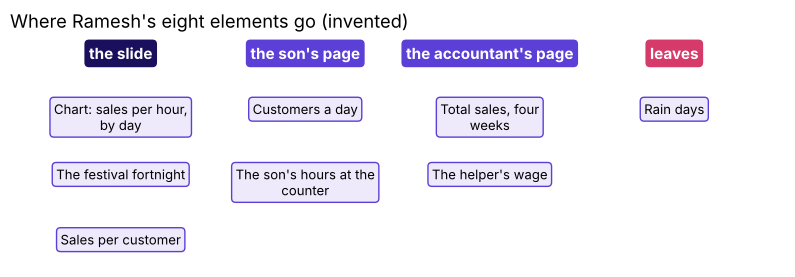

In [2]:
def route(e):
    """The sort: the caveat and what the claim needs stay; a named reader's question gets a page; the rest leaves."""
    if e.is_caveat == "yes" or e.supports_claim == "yes":
        return "the slide"
    return f"{e.whose_question}'s page" if e.whose_question else "leaves"

elements["goes_to"] = elements.apply(route, axis=1)
print(elements[["element", "goes_to"]].to_string(index=False))
where = elements.goes_to.value_counts()
check("three stay on the slide", where["the slide"] == 3)
check("two go to the son's page and two to the accountant's page",
      where["the son's page"] == 2 and where["the accountant's page"] == 2)
check("one leaves", where["leaves"] == 1)

fig, ax = plt.subplots(figsize=(10, 3.0))
columns = ["the slide", "the son's page", "the accountant's page", "leaves"]
for i, col in enumerate(columns):
    ax.text(i, 0.97, col, ha="center", va="top", weight="bold", color="white",
            bbox=dict(boxstyle="round", fc=[INK, VIOLET, VIOLET, ROSE][i], ec="none"))
    for j, name in enumerate(elements[elements.goes_to == col].element):
        ax.text(i, 0.76 - j * 0.24, textwrap.fill(name, 22), ha="center", va="top", fontsize=9.5,
                bbox=dict(boxstyle="round", fc=PALE, ec=VIOLET))
ax.set_xlim(-0.6, 3.6)
ax.set_ylim(0.15, 1)
ax.axis("off")
ax.set_title("Where Ramesh's eight elements go (invented)", loc="left")
plt.show()

**What happened.** The answer is b. Two elements carry the claim, the per-hour chart and
sales per customer, and the festival fortnight stays as the caveat. The son's page takes
customers a day and his hours at the counter; the accountant's page takes the four weeks'
totals and the helper's wage; rain days leave, because nobody will ask. Option a is the
trap: the two that carry the claim are right, and the caveat is forgotten.

## Where does each of the rest go?

Each appendix page is headed by its owner's question, so Ramesh can turn to it the moment
the question comes, and every number on it answers that question and nothing else.

In [3]:
questions = {"the son": "Did my extra hours at the counter bring customers?",
             "the accountant": "What did the longer hours cost, and what did they bring?"}
for owner, question in questions.items():
    print(f"Appendix page for {owner}: {question}")
    for _, e in elements[elements.whose_question == owner].iterrows():
        print(f"    {e.element}: {e.what_it_shows}")
off = elements[elements.goes_to != "the slide"]
check("an element off the slide leaves exactly when nobody will ask about it",
      ((off.goes_to == "leaves") == (off.whose_question == "")).all())
check("every page is headed by a question", all(q.endswith("?") for q in questions.values()))

Appendix page for the son: Did my extra hours at the counter bring customers?
    Customers a day: 119 in September, 126 in October
    The son's hours at the counter: 4 a day in September, 6 in October
Appendix page for the accountant: What did the longer hours cost, and what did they bring?
    Total sales, four weeks: Rs 3.33 lakh in September, Rs 3.53 lakh in October
    The helper's wage: Rs 85 an hour; the two extra hours cost Rs 170 a day
PASS an element off the slide leaves exactly when nobody will ask about it
PASS every page is headed by a question


## Can the caveat leave when the slide is crowded?

**The plausible wrong answer.** "The slide is crowded, so the festival fortnight goes to the
appendix with the rain days; it is only a detail." A hurried sort that asks only the first
two questions puts it there.

In [4]:
def hurried_route(e):
    """The same sort with the caveat question skipped."""
    if e.supports_claim == "yes":
        return "the slide"
    return f"{e.whose_question}'s page" if e.whose_question else "leaves"

festival = elements[elements.element == "The festival fortnight"].iloc[0]
print("the hurried sort sends the festival fortnight to:", hurried_route(festival))
print("the rule keeps it on:", route(festival))
check("the hurried sort drops the caveat", hurried_route(festival) == "leaves")
check("the rule keeps the caveat on the slide", route(festival) == "the slide")

the hurried sort sends the festival fortnight to: leaves
the rule keeps it on: the slide
PASS the hurried sort drops the caveat
PASS the rule keeps the caveat on the slide


**Why it is wrong.** The son will raise the festival first, and when he finds it missing he
calls the slide dishonest, after which Ramesh trusts nothing on it. **The check:** is the
caveat on the slide itself? **The fix:** ask the caveat question first; when the slide is
crowded, something else leaves instead.

## Does a chart obey the same rule?

The same 56 days, drawn the way a dashboard sends them: six series in mixed units, a legend,
a grid and a border. Then the makeover keeps only what the claim needs.

**Predict before you run.** How many of the cluttered chart's six series carry the claim
that each hour earns less?

a) One
b) Two
c) Three
d) All six

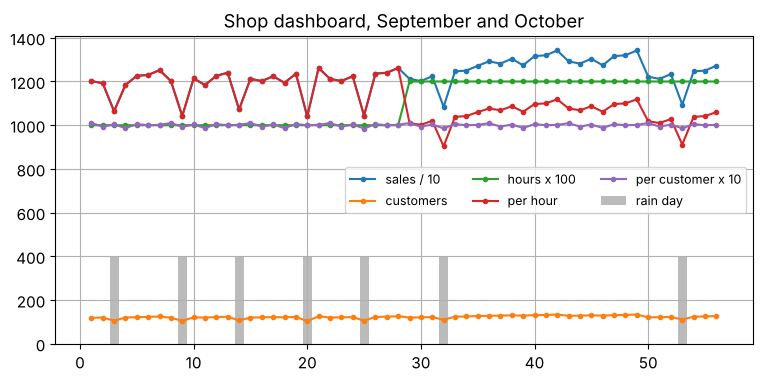

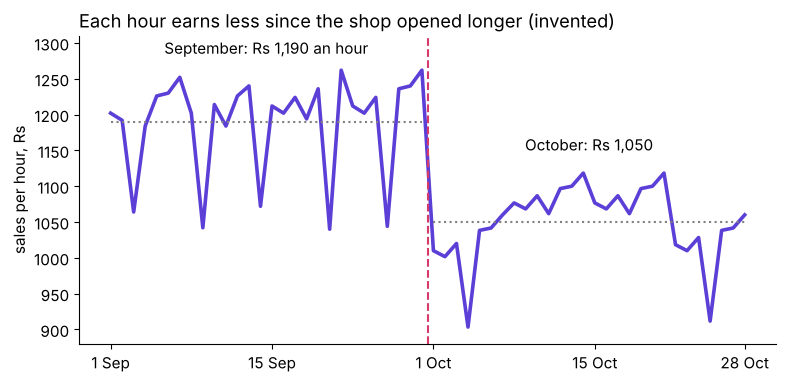

PASS one series of the six carries the claim


In [5]:
days = pd.read_csv("../data/C2_W04_D02_kirana_days_STUDENT.csv")
days["x"] = range(1, len(days) + 1)
days["per_hour"] = days.sales_rs / days.hours_open
series = {"sales / 10": days.sales_rs / 10, "customers": days.customers, "hours x 100": days.hours_open * 100,
          "per hour": days.per_hour, "per customer x 10": days.sales_rs / days.customers * 10}
fig, ax = plt.subplots(figsize=(9, 4))
for label, values in series.items():
    ax.plot(days.x, values, marker="o", ms=3, label=label)
ax.bar(days.x, (days.rain_day == "yes") * 400, color="#BBBBBB", label="rain day")
ax.grid(True)
ax.spines[["top", "right"]].set_visible(True)
ax.legend(ncol=3, fontsize=9)
ax.set_title("Shop dashboard, September and October")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(days.x, days.per_hour, color=VIOLET, lw=2.6)
ax.hlines(1190, 1, 28, color="gray", ls=":")
ax.hlines(1050, 29, 56, color="gray", ls=":")
ax.text(14.5, 1285, "September: Rs 1,190 an hour", ha="center")
ax.text(42.5, 1150, "October: Rs 1,050", ha="center")
ax.set_ylim(880, 1310)
ax.axvline(28.5, color=ROSE, ls="--")
ax.set_xticks([1, 15, 29, 43, 56], ["1 Sep", "15 Sep", "1 Oct", "15 Oct", "28 Oct"])
ax.set_ylabel("sales per hour, Rs")
ax.set_title("Each hour earns less since the shop opened longer (invented)", loc="left")
plt.show()
kept = ["per hour"]
check("one series of the six carries the claim", len(series) + 1 == 6 and len(kept) == 1)

**What happened.** The answer is a. Five of the six series leave, with the legend, the grid
and the border; one line and two labels stay, and the title says the claim. The test is the
one the elements met: does the claim need this ink? Storytelling with Data puts it as a
question to ask of every element, "Is it adding any informative value?", and takes out
whatever is not.

**Your turn.** Ramesh's accountant presents the same eight elements to the bank, and her
claim is different: the helper's two extra hours cost less than they bring. Mark which
elements her claim needs, run the same sort, and check that the caveat still stays. Fill
the blank, type the lines into the empty cell below and run them:

```python
bank = elements.copy()
bank["supports_claim"] = "no"
needs = ["The helper's wage", ___]               # the element that shows what the hours brought
bank.loc[bank.element.isin(needs), "supports_claim"] = "yes"
bank["goes_to"] = bank.apply(route, axis=1)
print(bank[["element", "goes_to"]].to_string(index=False))
check("the festival fortnight stays on the slide whatever the claim",
      bank.set_index("element").goes_to["The festival fortnight"] == "the slide")
check("the bank's slide keeps three elements", (bank.goes_to == "the slide").sum() == 3)
```

## Which rules does the chapter leave?

1. An element stays only if the claim cannot stand without it.
2. An element a named person will ask about goes to that person's page, headed by their
   question.
3. An element nobody will ask about leaves.
4. The caveat stays on the slide, even when the slide is crowded.

Named last: this is what to leave out, and the appendix. A chart obeys the same rule, one
series at a time.

**In the interview.** [F] What do you leave off the slide, and where does it go? Answer with
the drawer: one page per question a named role will ask, the caveat kept in sight.

**Where it is used next.** Chapter 4's notebook,
`C2_W04_D02_04_case_one_slide_answer_three_denominators_STUDENT.ipynb`, cuts Uber's
nine-number slide to its claim; chapter 5's notebook,
`C2_W04_D02_05_case_defending_under_challenge_evidence_STUDENT.ipynb`, builds one appendix
page for each of the three roles' questions.